# Load data: ICEWS

We are going to use the following libraries:

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
from scipy.sparse import coo_matrix, save_npz
from scipy.stats import rankdata, norm
import os
import json

We load the data from a `parquet` file and display some statistics.

In [2]:
path = r"C:\Users\carlo\OneDrive\Documents\blockdynamicnetworks\python\others\Hoff_2015_MultilinearTensorRegression\ICEWS_month_1995_2022_242c.parquet"
tensornetwork = pd.read_parquet(path)
tensornetwork["month"] = pd.to_datetime(tensornetwork["month"])
display(tensornetwork.head())
print(tensornetwork.shape)
print(tensornetwork.info())

,month,origin,destination,layer,weight
0,1994-12-01,Bangladesh,Bangladesh,Verbal-,1
1,1994-12-01,Barbados,Barbados,Material-,1
2,1994-12-01,Bosnia and Herzegovina,Serbia,Verbal+,1
3,1994-12-01,Canada,Canada,Material-,1
4,1994-12-01,Canada,Canada,Verbal+,1


(1437951, 5)
<class 'pandas.DataFrame'>
RangeIndex: 1437951 entries, 0 to 1437950
Data columns (total 5 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   month        1437951 non-null  datetime64[us]
 1   origin       1437951 non-null  str           
 2   destination  1437951 non-null  str           
 3   layer        1437951 non-null  str           
 4   weight       1437951 non-null  int32         
dtypes: datetime64[us](1), int32(1), str(3)
memory usage: 83.4 MB
None


We construct the adjacency matrices for all 242 countries and save them.

In [3]:
tensornetwork = tensornetwork[(tensornetwork["month"] >= "1995-01-01") & (tensornetwork["month"] <= "2022-12-01")].copy()
countries = sorted(set(tensornetwork["origin"]) | set(tensornetwork["destination"]))
months = pd.date_range(start="1995-01-01", end="2022-12-01", freq="MS")
layers = ["Material-", "Material+", "Verbal-", "Verbal+"]
index_countries = {c: i for i, c in enumerate(countries)}
index_months = {m: i for i, m in enumerate(months)}
index_layers = {l: i for i, l in enumerate(layers)}
N = len(countries)
T = len(months)
K = len(layers)
tensornetwork["i"] = tensornetwork["origin"].map(index_countries)
tensornetwork["j"] = tensornetwork["destination"].map(index_countries)
tensornetwork["t"] = tensornetwork["month"].map(index_months)
tensornetwork["k"] = tensornetwork["layer"].map(index_layers)
missing_indexes = tensornetwork[["i", "j", "t", "k"]].isna().sum()
print("Missing indexes:")
print(missing_indexes)
assert tensornetwork[["i", "j", "t", "k"]].notna().all().all()
tensornetwork[["i", "j", "t", "k"]] = tensornetwork[["i", "j", "t", "k"]].astype(int)
matrices = {}
for k, layer in enumerate(layers):
    for t, month in enumerate(months):
        data = tensornetwork[(tensornetwork["k"] == k) &(tensornetwork["t"] == t)]
        A = coo_matrix((data["weight"].to_numpy(), (data["i"].to_numpy(), data["j"].to_numpy())),shape=(N, N),dtype=np.int64).tocsr()
        matrices[(k, t)] = A
    print("Finalized layer:", layer)
matrices_serie = {}
for (k, t), A in matrices.items():
    matrices_serie[f"A_{k}_{t}"] = A
np.savez_compressed("ICEWS_month_matrices_242_c.npz", **matrices_serie)
metadata = {"countries": countries, "months": months.strftime("%Y-%m-%d").tolist(), "layers": layers}
with open("ICEWS_month_metadata_242c.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)
print("\nCountries:", N)
print("Months:", T)
print("Layers:", K)
print("Matrices:", len(matrices))
print("Total possible matrices:", T * K)

Missing indexes:
i    0
j    0
t    0
k    0
dtype: int64
Finalized layer: Material-
Finalized layer: Material+
Finalized layer: Verbal-
Finalized layer: Verbal+

Countries: 252
Months: 336
Layers: 4
Matrices: 1344
Total possible matrices: 1344


We consult a particular matrix.

Dimensions: (252, 252)
Connections: 3646
Events: 47615


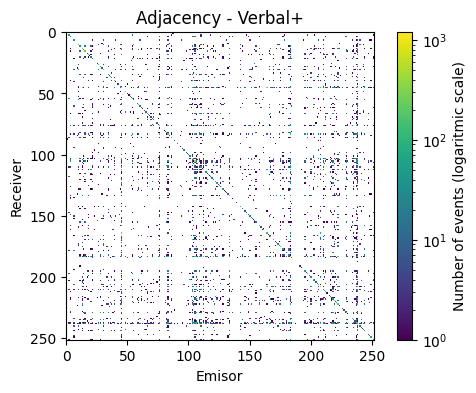

In [4]:

A = matrices[(3, 105)]
print("Dimensions:", A.shape)
print("Connections:", A.nnz)
print("Events:", A.sum())
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
plt.figure(figsize=(6, 4))
plt.imshow(A.toarray(), cmap="viridis", norm=LogNorm(vmin=1, vmax=A.toarray().max()), interpolation="nearest")
plt.colorbar(label="Number of events (logaritmic scale)")
plt.title("Adjacency - Verbal+")
plt.xlabel("Emisor")
plt.ylabel("Receiver")

plt.show()

Now, using a network aggregated over time and across layers, we evaluate the importance of each node by means of the PageRank metric.

In [5]:

aggnetwork = tensornetwork.groupby(["origin", "destination"],as_index=False)["weight"].sum()
aggnetwork = aggnetwork[aggnetwork["origin"] != aggnetwork["destination"]]
G = nx.from_pandas_edgelist(aggnetwork,source="origin",target="destination",edge_attr="weight",create_using=nx.DiGraph())
pagerank = nx.pagerank(G,alpha=0.85,weight="weight")
importance = pd.DataFrame({"country": list(pagerank.keys()), "pagerank": list(pagerank.values())})
importance = importance.sort_values("pagerank",ascending=False).reset_index(drop=True)
importance.index = importance.index + 1
importance.index.name = "ranking"
display(importance.head(50))

,country,pagerank
ranking,,
1,United States,0.100594
2,Russian Federation,0.051657
3,China,0.047604
4,Israel,0.024905
5,United Kingdom,0.024622
6,Japan,0.023751
7,Iran,0.022207
8,India,0.021972
9,France,0.020567


Following the methodology of Hoff (2015), and with the goal of reducing the number of null events, we select the L most relevant nodes for the multilayer dynamic network.

In [6]:
values_L = [10, 25, 30, 50, 75, 100, 242]
results_L = []
total_weight = tensornetwork["weight"].sum()
original_by_layer = tensornetwork.groupby("layer")["weight"].sum()
T = tensornetwork["month"].nunique()
K = len(layers)
for L in values_L:
    top_countries = set(importance.head(L)["country"])
    Lnetwork = tensornetwork[tensornetwork["origin"].isin(top_countries) & tensornetwork["destination"].isin(top_countries)]
    events = Lnetwork["weight"].sum()
    total_entries = L * L * K * T
    nonzero_entries = Lnetwork[["month", "origin", "destination", "layer"]].drop_duplicates().shape[0]
    zero_entries = total_entries - nonzero_entries
    zero_percentage = zero_entries / total_entries * 100
    result = {
        "L": L,
        "number_countries": len(top_countries),
        "events": events,
        "percentage": events / total_weight * 100,
        "connections": len(Lnetwork),
        "nonzero_entries": nonzero_entries,
        "zero_entries": zero_entries,
        "zero_percentage": zero_percentage
    }
    retained_by_layer = Lnetwork.groupby("layer")["weight"].sum()
    nonzero_by_layer = Lnetwork.groupby("layer").size()
    total_entries_layer = L * L * T
    for layer in layers:
        layer_events = retained_by_layer.get(layer, 0)
        original_events = original_by_layer.get(layer, 0)
        result[layer] = layer_events / original_events * 100 if original_events > 0 else 0
        layer_nonzero = nonzero_by_layer.get(layer, 0)
        result[f"zeros_{layer}"] = (total_entries_layer - layer_nonzero) / total_entries_layer * 100
    results_L.append(result)
comparison_L = pd.DataFrame(results_L)
display(comparison_L)

,L,number_countries,events,percentage,connections,nonzero_entries,zero_entries,zero_percentage,Material-,zeros_Material-,Material+,zeros_Material+,Verbal-,zeros_Verbal-,Verbal+,zeros_Verbal+
0,10,10,4597999,26.644489,69302,69302,65098,48.436012,30.370989,58.630952,25.135736,69.130952,33.524869,45.586310,24.300636,20.395833
1,25,25,8676612,50.279240,247228,247228,592772,70.568095,56.402721,77.003333,49.656195,84.531905,55.722395,73.069048,47.560477,47.668095
2,30,30,9476941,54.916987,304097,304097,905503,74.859706,60.876145,81.017196,55.208160,87.427910,59.820078,78.231812,52.310129,52.761905
3,50,50,12407763,71.900517,525864,525864,2834136,84.349286,77.477922,89.075952,74.378084,93.087738,77.634309,88.000119,69.115971,67.233333
4,75,75,14361157,83.220047,789781,789781,6770219,89.553161,87.713888,93.235979,84.863256,95.842011,86.822727,92.751852,81.205467,76.382804
5,100,100,15687179,90.904081,1035866,1035866,12404134,92.292664,93.002546,95.292351,91.256833,97.177262,92.261073,94.981488,90.051095,81.719554
6,242,242,17256464,99.997775,1437751,1437751,77272265,98.173357,99.995789,98.945725,99.998901,99.385430,99.992858,98.889249,99.999269,95.473023


In [7]:
output_path = os.path.dirname(path)
L = 50
top_countries = importance.head(L)["country"].tolist()
countries_top = sorted(top_countries)
print("Selected countries:", len(countries_top))
print(countries_top)

Selected countries: 50
['Afghanistan', 'Argentina', 'Australia', 'Azerbaijan', 'Brazil', 'Canada', 'China', 'Colombia', 'Croatia', 'Cuba', 'Egypt', 'France', 'Georgia', 'Germany', 'Greece', 'India', 'Indonesia', 'Iran', 'Iraq', 'Israel', 'Italy', 'Japan', 'Kenya', 'Lebanon', 'Libya', 'Mexico', 'New Zealand', 'Nigeria', 'North Korea', 'Occupied Palestinian Territory', 'Pakistan', 'Philippines', 'Poland', 'Romania', 'Russian Federation', 'Saudi Arabia', 'Serbia', 'South Africa', 'South Korea', 'Spain', 'Sudan', 'Syria', 'Taiwan', 'Thailand', 'Turkey', 'Ukraine', 'United Kingdom', 'United States', 'Venezuela', 'Vietnam']


In [8]:
top50_network = tensornetwork[tensornetwork["origin"].isin(countries_top) & tensornetwork["destination"].isin(countries_top)].copy()
top50_network = top50_network[["month", "origin", "destination", "layer", "weight"]]
top50_network = top50_network.sort_values(["month", "layer", "origin", "destination"]).reset_index(drop=True)
top50_parquet = os.path.join(output_path, "ICEWS_top50_monthly.parquet")
top50_network.to_parquet(top50_parquet,index=False,compression="zstd")
print("Top 50 network:", top50_network.shape)
print("Total events:", top50_network["weight"].sum())
total_events = tensornetwork["weight"].sum()
top50_events = top50_network["weight"].sum()
print("Original events:", total_events)
print("Top 50 events:", top50_events)
print("Percentage retained:", round(top50_events / total_events * 100, 2),"%")
layer_comparison = (top50_network.groupby("layer")["weight"].sum() / tensornetwork.groupby("layer")["weight"].sum()* 100)
print(layer_comparison.round(2))

Top 50 network: (525864, 5)
Total events: 12407763
Original events: 17256848
Top 50 events: 12407763
Percentage retained: 71.9 %
layer
Material+    74.38
Material-    77.48
Verbal+      69.12
Verbal-      77.63
Name: weight, dtype: float64


In [9]:
countries_top = importance.head(50)["country"].tolist()
months = pd.date_range(start="1995-01-01", end="2022-12-01",freq="MS")
layers = ["Material-", "Material+", "Verbal-", "Verbal+"]
top50_network = tensornetwork[tensornetwork["origin"].isin(countries_top) & tensornetwork["destination"].isin(countries_top)].copy()
index_countries = {country: i for i, country in enumerate(countries_top)}
index_months = {month: i for i, month in enumerate(months)}
index_layers = {layer: i for i, layer in enumerate(layers)}
N = len(countries_top)
T = len(months)
K = len(layers)
top50_network["month"] = pd.to_datetime(top50_network["month"])
top50_network["i"] = top50_network["origin"].map(index_countries)
top50_network["j"] = top50_network["destination"].map(index_countries)
top50_network["t"] = top50_network["month"].map(index_months)
top50_network["k"] = top50_network["layer"].map(index_layers)
assert top50_network[["i", "j", "t", "k"]].notna().all().all()
top50_network[["i", "j", "t", "k"]] = top50_network[["i", "j", "t", "k"]].astype(int)
matrices = {}
for k, layer in enumerate(layers):
    for t, month in enumerate(months):
        data = top50_network[(top50_network["k"] == k) & (top50_network["t"] == t)]
        A = coo_matrix((data["weight"].to_numpy(), (data["i"].to_numpy(),data["j"].to_numpy())),shape=(N, N),dtype=np.int64).tocsr()
        matrices[(k, t)] = A
    print("Finalized layer:", layer)
matrices_serie = {}
for (k, t), A in matrices.items():
    matrices_serie[f"A_{k}_{t}"] = A
np.savez_compressed("ICEWS_top50_month_matrices.npz",**matrices_serie)
metadata = {"countries": countries_top,"months": months.strftime("%Y-%m-%d").tolist(),"layers": layers}
with open("ICEWS_top50_month_metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)
print("\nCountries:", N)
print("Months:", T)
print("Layers:", K)
print("Matrices:", len(matrices))
print("Expected matrices:", N * 0 + T * K)
matrix_total = sum(A.sum() for A in matrices.values())
print("Original top 50 events:", top50_network["weight"].sum())
print("Matrix total:", matrix_total)
print("Matrix shape:", matrices[(0, 0)].shape)
print("Number of matrices:", len(matrices))

Finalized layer: Material-
Finalized layer: Material+
Finalized layer: Verbal-
Finalized layer: Verbal+

Countries: 50
Months: 336
Layers: 4
Matrices: 1344
Expected matrices: 1344
Original top 50 events: 12407763
Matrix total: 12407763
Matrix shape: (50, 50)
Number of matrices: 1344


Dimensions: (50, 50)
Connections: 1099
Events: 33540


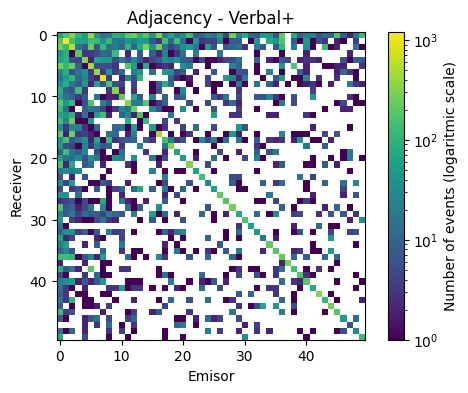

In [10]:

A = matrices[(3, 105)]
print("Dimensions:", A.shape)
print("Connections:", A.nnz)
print("Events:", A.sum())
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
plt.figure(figsize=(6, 4))
plt.imshow(A.toarray(), cmap="viridis", norm=LogNorm(vmin=1, vmax=A.toarray().max()), interpolation="nearest")
plt.colorbar(label="Number of events (logaritmic scale)")
plt.title("Adjacency - Verbal+")
plt.xlabel("Emisor")
plt.ylabel("Receiver")

plt.show()

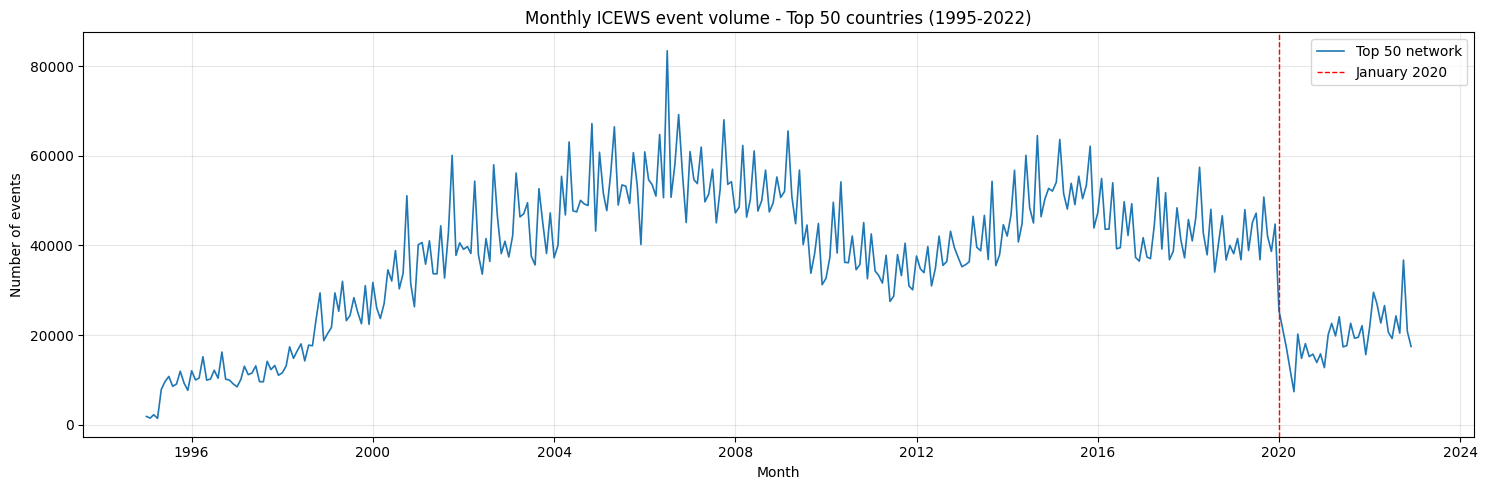

Total events: 12407763
Number of months: 336
Months without events: 0
Average monthly events: 36927.87


In [56]:

top50_monthly_events = (top50_network.groupby("month")["weight"].sum().reindex(months, fill_value=0))
plt.figure(figsize=(15, 5))
plt.plot(top50_monthly_events.index,top50_monthly_events.values,linewidth=1.2,label="Top 50 network")
plt.axvline(pd.Timestamp("2020-01-01"),color="red",linestyle="--",linewidth=1,label="January 2020")
plt.title("Monthly ICEWS event volume - Top 50 countries (1995-2022)")
plt.xlabel("Month")
plt.ylabel("Number of events")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Total events:", top50_monthly_events.sum())
print("Number of months:", len(top50_monthly_events))
print("Months without events:", (top50_monthly_events == 0).sum())
print("Average monthly events:", round(top50_monthly_events.mean(), 2))

In [91]:

results = []

for k, layer in enumerate(layers):

    # Apilar las matrices mensuales de una capa
    for i in range(N):
        for j in range(N):

            # Extraer los conteos de los 336 meses
            counts = np.array([
                matrices[(k, t)][i, j]
                for t in range(T)
            ]).flatten()

            mean_ij = counts.mean()
            var_ij = counts.var(ddof=1)

            dispersion = (
                var_ij / mean_ij
                if mean_ij > 0 else np.nan
            )

            results.append({
                "origin": countries_top[i],
                "destination": countries_top[j],
                "layer": layer,
                "mean": mean_ij,
                "variance": var_ij,
                "dispersion": dispersion,
                "total_events": counts.sum(),
                "months_active": np.count_nonzero(counts)
            })

dispersion_df = pd.DataFrame(results)

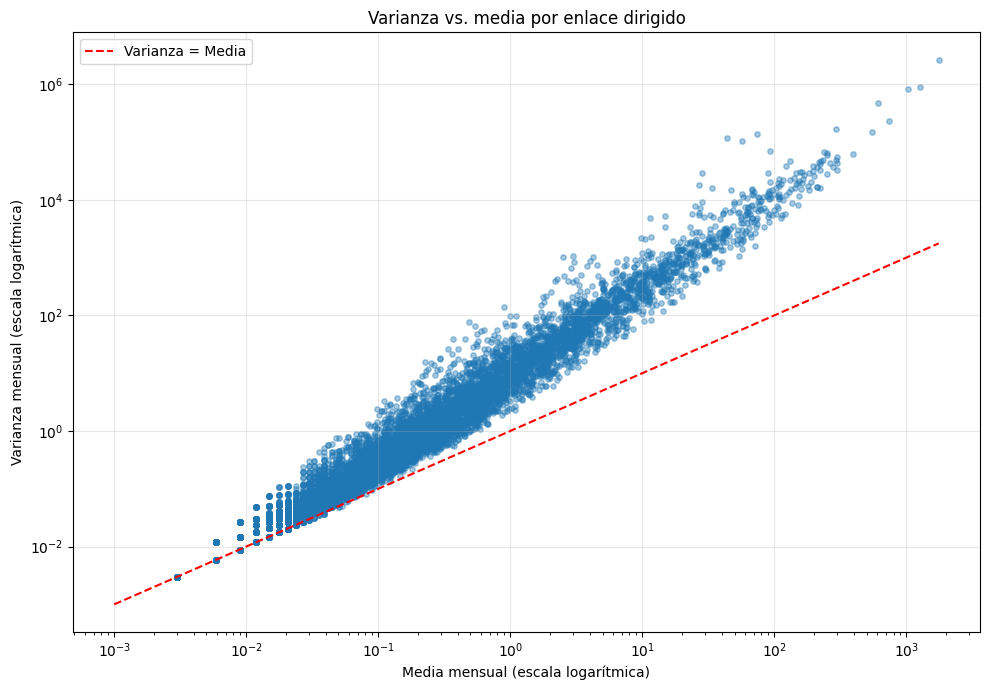

                 number_of_links  percentage
classification                              
Sobredispersión             7596       75.96
Equidispersión              1443       14.43
Sin eventos                  961        9.61
                  origin                     destination      layer  \
172               Israel                         Lebanon  Material-   
69    Russian Federation                         Ukraine  Material-   
18         United States                     Afghanistan  Material-   
7857               India                           India    Verbal+   
1103             Lebanon                          Israel  Material-   
5357               India                           India    Verbal-   
9387             Nigeria                         Nigeria    Verbal+   
12         United States                            Iraq  Material-   
357                India                           India  Material-   
15         United States                           Syria  Materia

In [97]:
def classify_dispersion(x):

    if pd.isna(x):
        return "Sin eventos"

    elif np.isclose(x, 1, atol=0.1):
        return "Equidispersión"

    elif x > 1.1:
        return "Sobredispersión"

    elif x < 0.9:
        return "Subdispersión"

    else:
        return "Cercano a equidispersión"


dispersion_df["classification"] = (
    dispersion_df["dispersion"]
    .apply(classify_dispersion)
)

df_plot = dispersion_df[
    (dispersion_df["mean"] > 0) &
    (dispersion_df["variance"] > 0)
].copy()

plt.figure(figsize=(10, 7))

plt.scatter(
    df_plot["mean"],
    df_plot["variance"],
    alpha=0.4,
    s=15
)

xmax = df_plot["mean"].max()
ymax = df_plot["variance"].max()

plt.plot(
    [0.001, min(xmax, ymax)],
    [0.001, min(xmax, ymax)],
    "r--",
    label="Varianza = Media"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Media mensual (escala logarítmica)")
plt.ylabel("Varianza mensual (escala logarítmica)")
plt.title("Varianza vs. media por enlace dirigido")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

summary = (
    dispersion_df["classification"]
    .value_counts()
    .to_frame("number_of_links")
)

summary["percentage"] = (
    summary["number_of_links"] /
    summary["number_of_links"].sum() * 100
)

print(summary)


most_overdispersed = (
    dispersion_df
    .query("total_events > 0")
    .sort_values("dispersion", ascending=False)
    .head(20)
)

print(most_overdispersed)

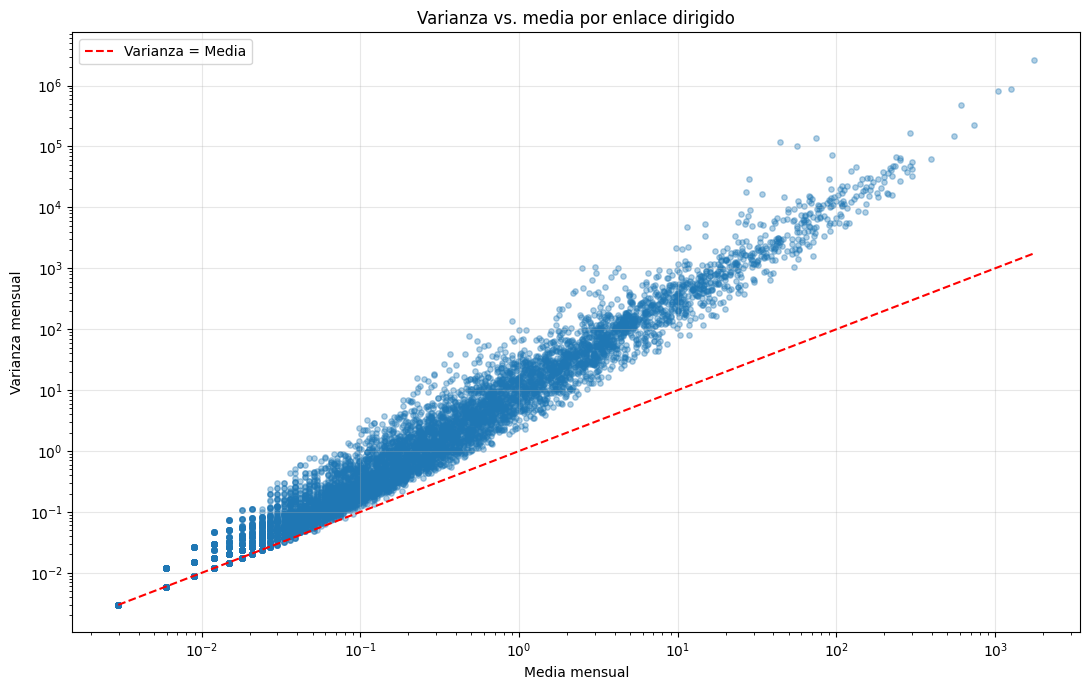


========== DISPERSION GENERAL ==========
                 number_of_links  percentage
classification                              
Sobredispersión             7596       75.96
Equidispersión              1443       14.43
Sin eventos                  961        9.61

========== DISPERSION POR CAPA ==========
classification  Equidispersión  Sin eventos  Sobredispersión  Total  \
layer                                                                 
Material+                  571          440             1489   2500   
Material-                  389          249             1862   2500   
Verbal+                     37            8             2455   2500   
Verbal-                    446          264             1790   2500   

classification  % Sobredispersión  
layer                              
Material+                   59.56  
Material-                   74.48  
Verbal+                     98.20  
Verbal-                     71.60  


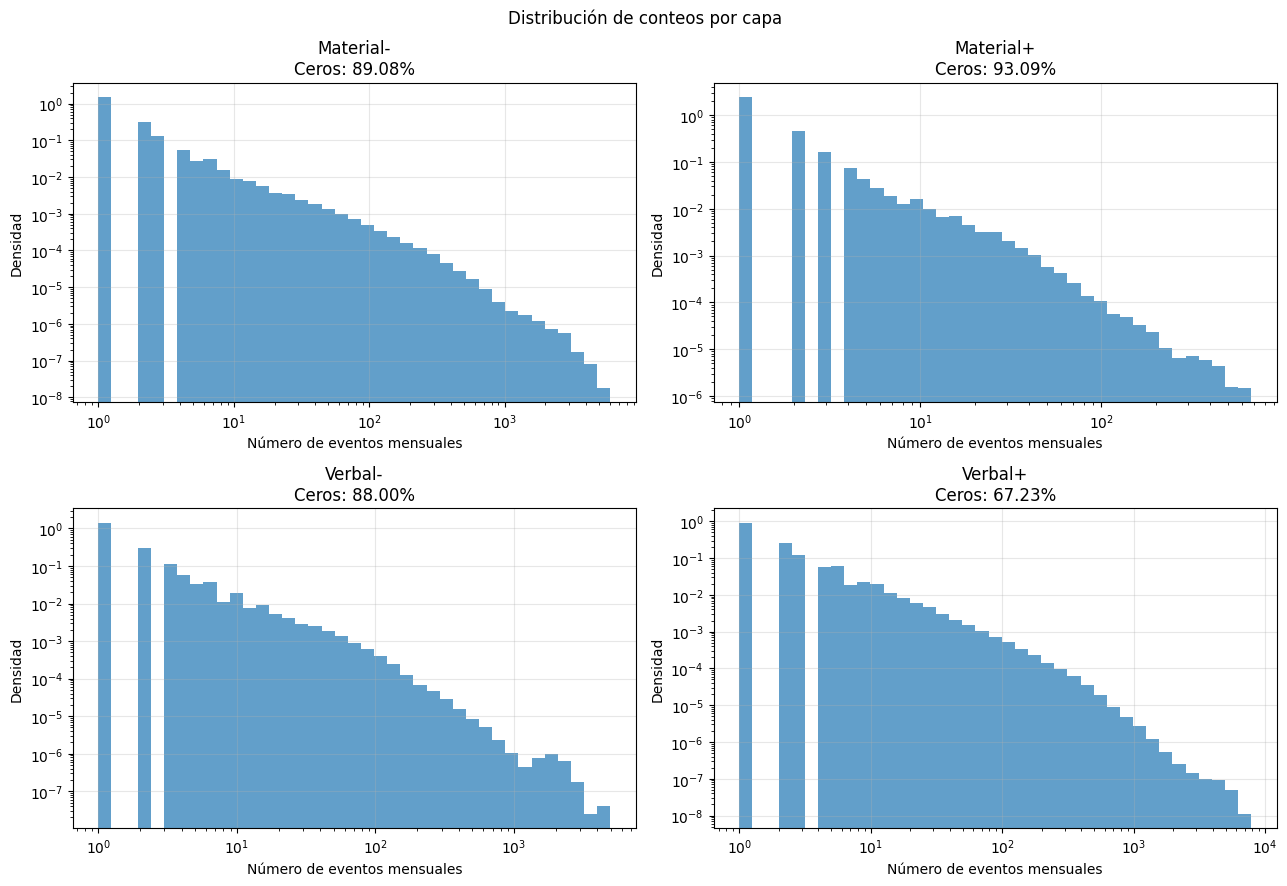

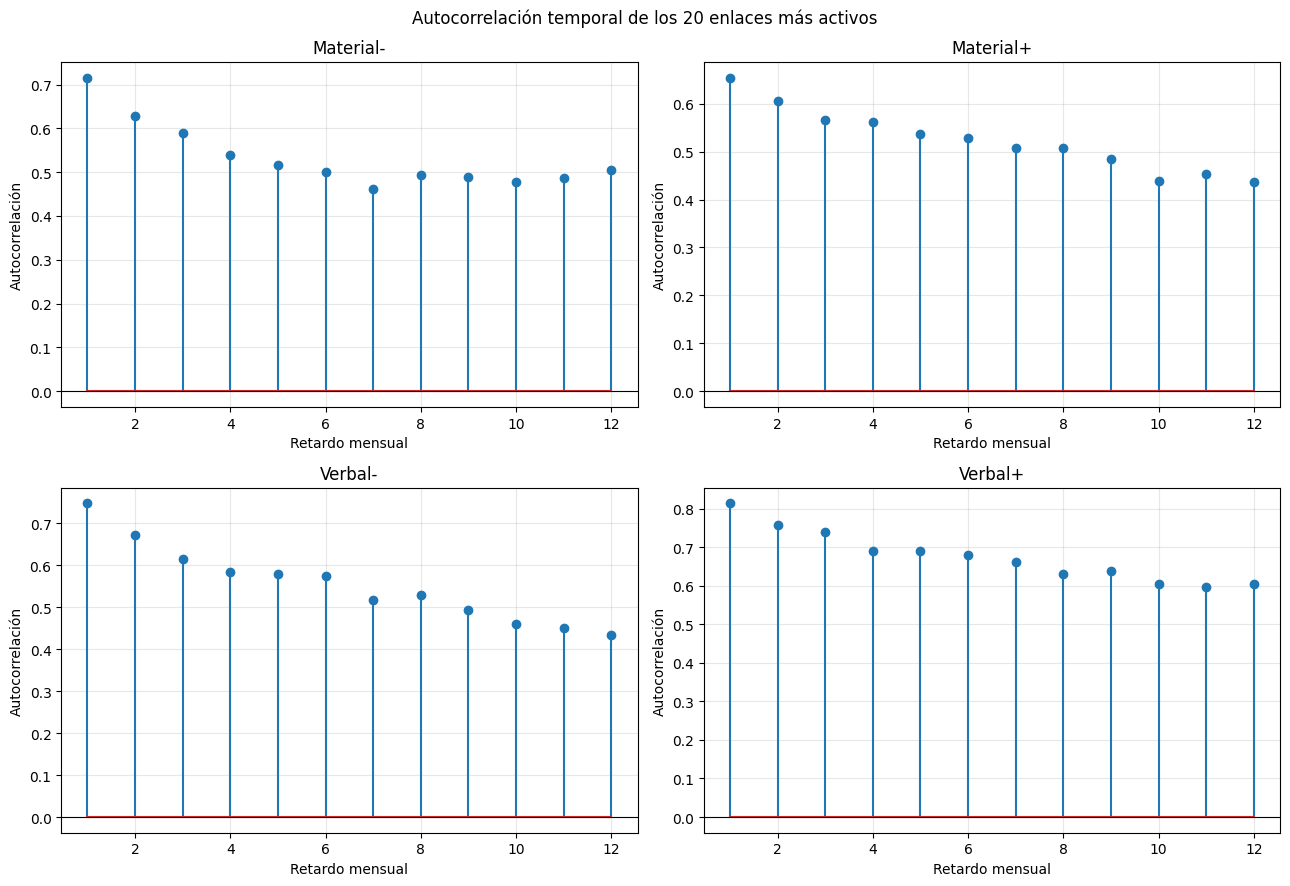


========== AUTOCORRELACION ==========
lag              1         3         6         12
layer                                            
Material+  0.654487  0.565620  0.528183  0.435817
Material-  0.715980  0.589672  0.501467  0.504364
Verbal+    0.813818  0.738498  0.680640  0.603501
Verbal-    0.747593  0.615924  0.574642  0.434538

========== COMPARACION POISSON VS BINOMIAL NEGATIVA ==========
              r_MLE  r_momentos   AIC_Poisson        AIC_NB     Delta_AIC   BIC_Poisson        BIC_NB     Delta_BIC
layer                                                                                                              
Material-  0.247169    1.092290  3.337692e+06  8.609043e+05 -2.476787e+06  3.363660e+06  8.868840e+05 -2.476776e+06
Material+  0.295462    1.031821  8.837077e+05  5.114161e+05 -3.722916e+05  9.072897e+05  5.350095e+05 -3.722802e+05
Verbal-    0.356651    1.207862  2.516088e+06  8.996124e+05 -1.616475e+06  2.541868e+06  9.254040e+05 -1.616464e+06
Verbal+    0.2750

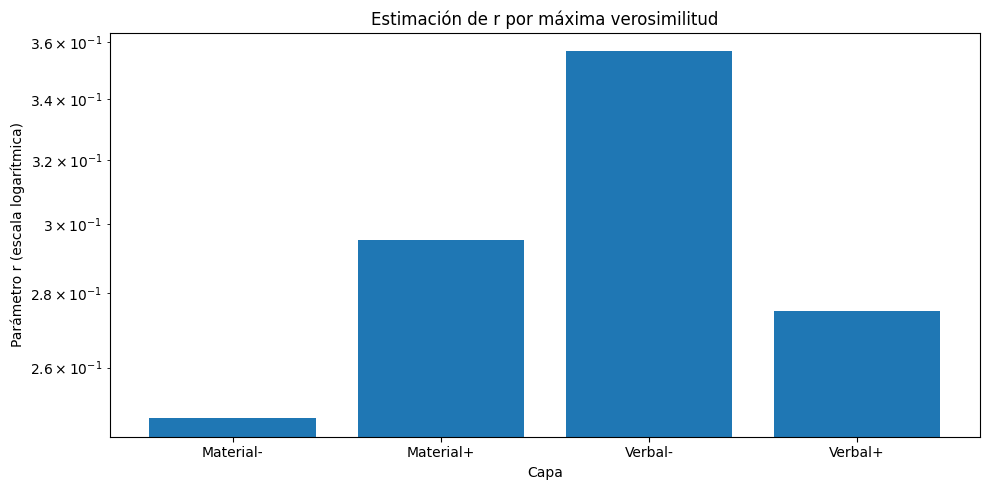


========== 20 ENLACES MAS SOBREDISPERSOS ==========
            origin                    destination     layer        mean     variance  dispersion  total_events  months_active  classification
            Israel                        Lebanon Material-   43.922619 1.189060e+05 2707.169805         14758            317 Sobredispersión
Russian Federation                        Ukraine Material-   74.196429 1.363694e+05 1837.951563         24930            233 Sobredispersión
     United States                    Afghanistan Material-   56.627976 1.027297e+05 1814.115635         19027            285 Sobredispersión
             India                          India   Verbal+ 1761.660714 2.669978e+06 1515.602880        591918            300 Sobredispersión
           Lebanon                         Israel Material-   28.190476 2.927325e+04 1038.409106          9472            296 Sobredispersión
             India                          India   Verbal- 1034.434524 8.195553e+05  792.27370

In [98]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import gammaln
from scipy.optimize import minimize_scalar
from statsmodels.tsa.stattools import acf

# ============================================================
# 1. CONSTRUIR SERIES TEMPORALES POR ENLACE Y CAPA
# ============================================================

series = {}
results = []

for k, layer in enumerate(layers):

    A_serie = np.stack(
        [matrices[(k, t)].toarray() for t in range(T)],
        axis=2
    )

    Y = A_serie.reshape(N * N, T)

    series[layer] = Y

    for idx in range(N * N):

        i = idx // N
        j = idx % N

        counts = Y[idx, :]

        mean_ij = counts.mean()
        var_ij = counts.var(ddof=1)

        dispersion = (
            var_ij / mean_ij
            if mean_ij > 0 else np.nan
        )

        results.append({
            "origin": countries_top[i],
            "destination": countries_top[j],
            "layer": layer,
            "mean": mean_ij,
            "variance": var_ij,
            "dispersion": dispersion,
            "total_events": counts.sum(),
            "months_active": np.count_nonzero(counts)
        })

dispersion_df = pd.DataFrame(results)


# ============================================================
# 2. CLASIFICACION DE LA DISPERSION
# ============================================================

def classify_dispersion(x):

    if pd.isna(x):
        return "Sin eventos"

    elif 0.9 <= x <= 1.1:
        return "Equidispersión"

    elif x > 1.1:
        return "Sobredispersión"

    else:
        return "Subdispersión"


dispersion_df["classification"] = (
    dispersion_df["dispersion"].apply(classify_dispersion)
)


# ============================================================
# 3. VARIANZA VS MEDIA
# ============================================================

df_plot = dispersion_df[
    (dispersion_df["mean"] > 0) &
    (dispersion_df["variance"] > 0)
]

plt.figure(figsize=(11, 7))

plt.scatter(
    df_plot["mean"],
    df_plot["variance"],
    alpha=0.35,
    s=15
)

xmin = df_plot["mean"].min()
xmax = df_plot["mean"].max()

plt.plot(
    [xmin, xmax],
    [xmin, xmax],
    "r--",
    label="Varianza = Media"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Media mensual")
plt.ylabel("Varianza mensual")
plt.title("Varianza vs. media por enlace dirigido")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 4. RESUMEN GENERAL Y POR CAPA
# ============================================================

print("\n========== DISPERSION GENERAL ==========")

summary = (
    dispersion_df["classification"]
    .value_counts()
    .to_frame("number_of_links")
)

summary["percentage"] = (
    summary["number_of_links"] /
    summary["number_of_links"].sum() * 100
)

print(summary)


print("\n========== DISPERSION POR CAPA ==========")

summary_layers = (
    dispersion_df
    .groupby(["layer", "classification"])
    .size()
    .unstack(fill_value=0)
)

summary_layers["Total"] = summary_layers.sum(axis=1)

summary_layers["% Sobredispersión"] = (
    summary_layers.get("Sobredispersión", 0) /
    summary_layers["Total"] * 100
)

print(summary_layers)


# ============================================================
# 5. DISTRIBUCION DE LOS CONTEOS POR CAPA
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, layer in zip(axes.flatten(), layers):

    Y = series[layer].flatten()

    zeros = np.mean(Y == 0) * 100
    positive = Y[Y > 0]

    if len(positive) > 0:

        bins = np.logspace(
            0,
            np.log10(max(positive.max(), 2) + 1),
            40
        )

        ax.hist(
            positive,
            bins=bins,
            density=True,
            alpha=0.7
        )

        ax.set_xscale("log")
        ax.set_yscale("log")

    ax.set_title(
        f"{layer}\nCeros: {zeros:.2f}%"
    )

    ax.set_xlabel("Número de eventos mensuales")
    ax.set_ylabel("Densidad")
    ax.grid(alpha=0.3)

plt.suptitle("Distribución de conteos por capa")
plt.tight_layout()
plt.show()


# ============================================================
# 6. DEPENDENCIA TEMPORAL: AUTOCORRELACION
# ============================================================

lags = [1, 3, 6, 12]
acf_results = []

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, layer in zip(axes.flatten(), layers):

    Y = series[layer]

    # Seleccionar los 20 enlaces con mayor actividad
    top_idx = np.argsort(Y.sum(axis=1))[-20:]

    acf_values = []

    for idx in top_idx:

        x = Y[idx, :]

        if np.std(x) == 0:
            continue

        acf_vals = acf(
            x,
            nlags=12,
            fft=True,
            missing="raise"
        )

        acf_values.append(acf_vals)

    if len(acf_values) > 0:

        acf_matrix = np.array(acf_values)

        median_acf = np.median(acf_matrix, axis=0)

        ax.stem(
            np.arange(1, 13),
            median_acf[1:]
        )

        for lag in lags:

            acf_results.append({
                "layer": layer,
                "lag": lag,
                "median_acf": median_acf[lag]
            })

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(layer)
    ax.set_xlabel("Retardo mensual")
    ax.set_ylabel("Autocorrelación")
    ax.grid(alpha=0.3)

plt.suptitle("Autocorrelación temporal de los 20 enlaces más activos")
plt.tight_layout()
plt.show()

acf_df = pd.DataFrame(acf_results)

print("\n========== AUTOCORRELACION ==========")
print(acf_df.pivot(
    index="layer",
    columns="lag",
    values="median_acf"
))


# ============================================================
# 7. ESTIMACION DEL PARAMETRO r DE BINOMIAL NEGATIVA
#    PARAMETRIZACION NB2:
#    Var(Y) = mu + mu^2/r
# ============================================================

def estimate_nb_parameters(Y):

    # Eliminar enlaces sin eventos
    Y_active = Y[Y.sum(axis=1) > 0].astype(float)

    n_links, n_months = Y_active.shape

    # Media específica para cada enlace
    mu = Y_active.mean(axis=1)

    # Repetir medias para cada observación mensual
    MU = np.repeat(mu[:, None], n_months, axis=1)

    # Log-verosimilitud Poisson
    ll_poisson = np.sum(
        Y_active * np.log(MU)
        - MU
        - gammaln(Y_active + 1)
    )

    # Log-verosimilitud binomial negativa NB2
    def nb_loglik(log_r):

        r = np.exp(log_r)

        ll = (
            gammaln(Y_active + r)
            - gammaln(r)
            - gammaln(Y_active + 1)
            + r * np.log(r / (r + MU))
            + Y_active * np.log(MU / (r + MU))
        )

        return np.sum(ll)

    # Maximizar la verosimilitud respecto a log(r)
    optimization = minimize_scalar(
        lambda log_r: -nb_loglik(log_r),
        bounds=(np.log(1e-3), np.log(1e8)),
        method="bounded"
    )

    r_hat = np.exp(optimization.x)

    ll_nb = nb_loglik(optimization.x)

    # Estimación alternativa mediante momentos
    sample_var = Y_active.var(axis=1, ddof=1)

    numerator = np.sum(
        (n_months - 1) * (sample_var - mu)
    )

    denominator = np.sum(
        (n_months - 1) * mu**2
    )

    inv_r_mom = numerator / denominator

    r_mom = (
        1 / inv_r_mom
        if inv_r_mom > 0 else np.inf
    )

    # Criterios de información
    n_obs = Y_active.size

    # Cada enlace tiene una media estimada
    k_poisson = n_links
    k_nb = n_links + 1

    aic_poisson = -2 * ll_poisson + 2 * k_poisson
    aic_nb = -2 * ll_nb + 2 * k_nb

    bic_poisson = (
        -2 * ll_poisson + k_poisson * np.log(n_obs)
    )

    bic_nb = (
        -2 * ll_nb + k_nb * np.log(n_obs)
    )

    return {
        "r_MLE": r_hat,
        "r_momentos": r_mom,
        "logLik_Poisson": ll_poisson,
        "logLik_NB": ll_nb,
        "AIC_Poisson": aic_poisson,
        "AIC_NB": aic_nb,
        "Delta_AIC": aic_nb - aic_poisson,
        "BIC_Poisson": bic_poisson,
        "BIC_NB": bic_nb,
        "Delta_BIC": bic_nb - bic_poisson,
        "n_links": n_links,
        "n_observations": n_obs,
        "convergencia": optimization.success,
        "limite_superior": optimization.x > np.log(1e8) - 0.01
    }


# Estimar r por capa
nb_results = []

for layer in layers:

    estimates = estimate_nb_parameters(series[layer])

    estimates["layer"] = layer

    nb_results.append(estimates)

nb_df = pd.DataFrame(nb_results).set_index("layer")


# ============================================================
# 8. RESULTADOS DE SELECCION DEL MODELO
# ============================================================

print("\n========== COMPARACION POISSON VS BINOMIAL NEGATIVA ==========")

print(
    nb_df[[
        "r_MLE",
        "r_momentos",
        "AIC_Poisson",
        "AIC_NB",
        "Delta_AIC",
        "BIC_Poisson",
        "BIC_NB",
        "Delta_BIC"
    ]].to_string()
)


# ============================================================
# 9. INTERPRETACION DEL PARAMETRO r
# ============================================================

print("\n========== INTERPRETACION DE r ==========")

for layer, row in nb_df.iterrows():

    r = row["r_MLE"]

    print(f"\nCapa: {layer}")
    print(f"r estimado por MLE: {r:.6f}")
    print(f"r estimado por momentos: {row['r_momentos']:.6f}")

    if row["limite_superior"]:
        print("Advertencia: r alcanza el límite superior de búsqueda.")

    if row["Delta_AIC"] < 0:
        print("AIC: favorece la binomial negativa.")
    else:
        print("AIC: favorece Poisson.")

    if row["Delta_BIC"] < 0:
        print("BIC: favorece la binomial negativa.")
    else:
        print("BIC: favorece Poisson.")

    print(
        f"Delta AIC: {row['Delta_AIC']:.2f} | "
        f"Delta BIC: {row['Delta_BIC']:.2f}"
    )


# ============================================================
# 10. VISUALIZACION DE LOS VALORES ESTIMADOS DE r
# ============================================================

plt.figure(figsize=(10, 5))

plt.bar(
    nb_df.index,
    nb_df["r_MLE"]
)

plt.yscale("log")

plt.ylabel("Parámetro r (escala logarítmica)")
plt.xlabel("Capa")
plt.title("Estimación de r por máxima verosimilitud")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 11. IDENTIFICAR LOS ENLACES MAS SOBREDISPERSOS
# ============================================================

most_overdispersed = (
    dispersion_df
    .query("total_events > 0")
    .sort_values("dispersion", ascending=False)
    .head(20)
)

print("\n========== 20 ENLACES MAS SOBREDISPERSOS ==========")
print(most_overdispersed.to_string(index=False))


# ============================================================
# 12. EXPORTAR RESULTADOS
# ============================================================

dispersion_df.to_csv(
    "ICEWS_dispersion_by_directed_edge.csv",
    index=False
)

nb_df.to_csv(
    "ICEWS_negative_binomial_parameters.csv"
)

acf_df.to_csv(
    "ICEWS_temporal_autocorrelation.csv",
    index=False
)

summary_layers.to_csv(
    "ICEWS_dispersion_by_layer.csv"
)

print("\nAnálisis finalizado. Resultados exportados.")


## Normal transformation

In [53]:
N = len(countries_top)
T = len(months)
K = len(layers)
index_countries = {country: i for i, country in enumerate(countries_top)}
index_months = {month: i for i, month in enumerate(months)}
index_layers = {layer: i for i, layer in enumerate(layers)}
top50_network["month"] = pd.to_datetime(top50_network["month"])
top50_network["i"] = top50_network["origin"].map(index_countries)
top50_network["j"] = top50_network["destination"].map(index_countries)
top50_network["t"] = top50_network["month"].map(index_months)
top50_network["k"] = top50_network["layer"].map(index_layers)
assert top50_network[["i", "j", "t", "k"]].notna().all().all()
Y_raw = np.zeros((K, N, N, T), dtype=np.float64)
Y_raw[
    top50_network["k"].to_numpy(dtype=int),
    top50_network["i"].to_numpy(dtype=int),
    top50_network["j"].to_numpy(dtype=int),
    top50_network["t"].to_numpy(dtype=int)
] = top50_network["weight"].to_numpy(dtype=float)
Y_normal = np.zeros_like(Y_raw, dtype=np.float64)
series_means = np.zeros((K, N, N), dtype=np.float64)
series_stds = np.zeros((K, N, N), dtype=np.float64)
for k in range(K):
    for i in range(N):
        for j in range(N):
            series = Y_raw[k, i, j, :]
            mean_value = series.mean()
            std_value = series.std(ddof=1)
            series_means[k, i, j] = mean_value
            series_stds[k, i, j] = std_value
            if std_value == 0:
                Y_normal[k, i, j, :] = mean_value
                continue
            ranks = rankdata(series, method="average")
            probabilities = (ranks - 0.5) / T
            normal_scores = norm.ppf(probabilities)
            normal_scores = (normal_scores - normal_scores.mean()) / normal_scores.std(ddof=1)
            Y_normal[k, i, j, :] = mean_value + std_value * normal_scores
print("Original tensor shape:", Y_raw.shape)
print("Transformed tensor shape:", Y_normal.shape)
print("Countries:", N)
print("Months:", T)
print("Layers:", K)
np.savez_compressed("ICEWS_top50_month_normal.npz",Y_normal=Y_normal)
metadata_normal = {"countries": countries_top, "months": months.strftime("%Y-%m-%d").tolist(),
    "layers": layers, "transformation": "Individual normal quantile transformation preserving original mean and variance",
    "dimensions": list(Y_normal.shape),"preserved_moments": ["mean", "variance"]}
with open("ICEWS_top50_month_normal_metadata.json","w", encoding="utf-8") as f:
    json.dump(metadata_normal, f, ensure_ascii=False, indent=4)

Original tensor shape: (4, 50, 50, 336)
Transformed tensor shape: (4, 50, 50, 336)
Countries: 50
Months: 336
Layers: 4


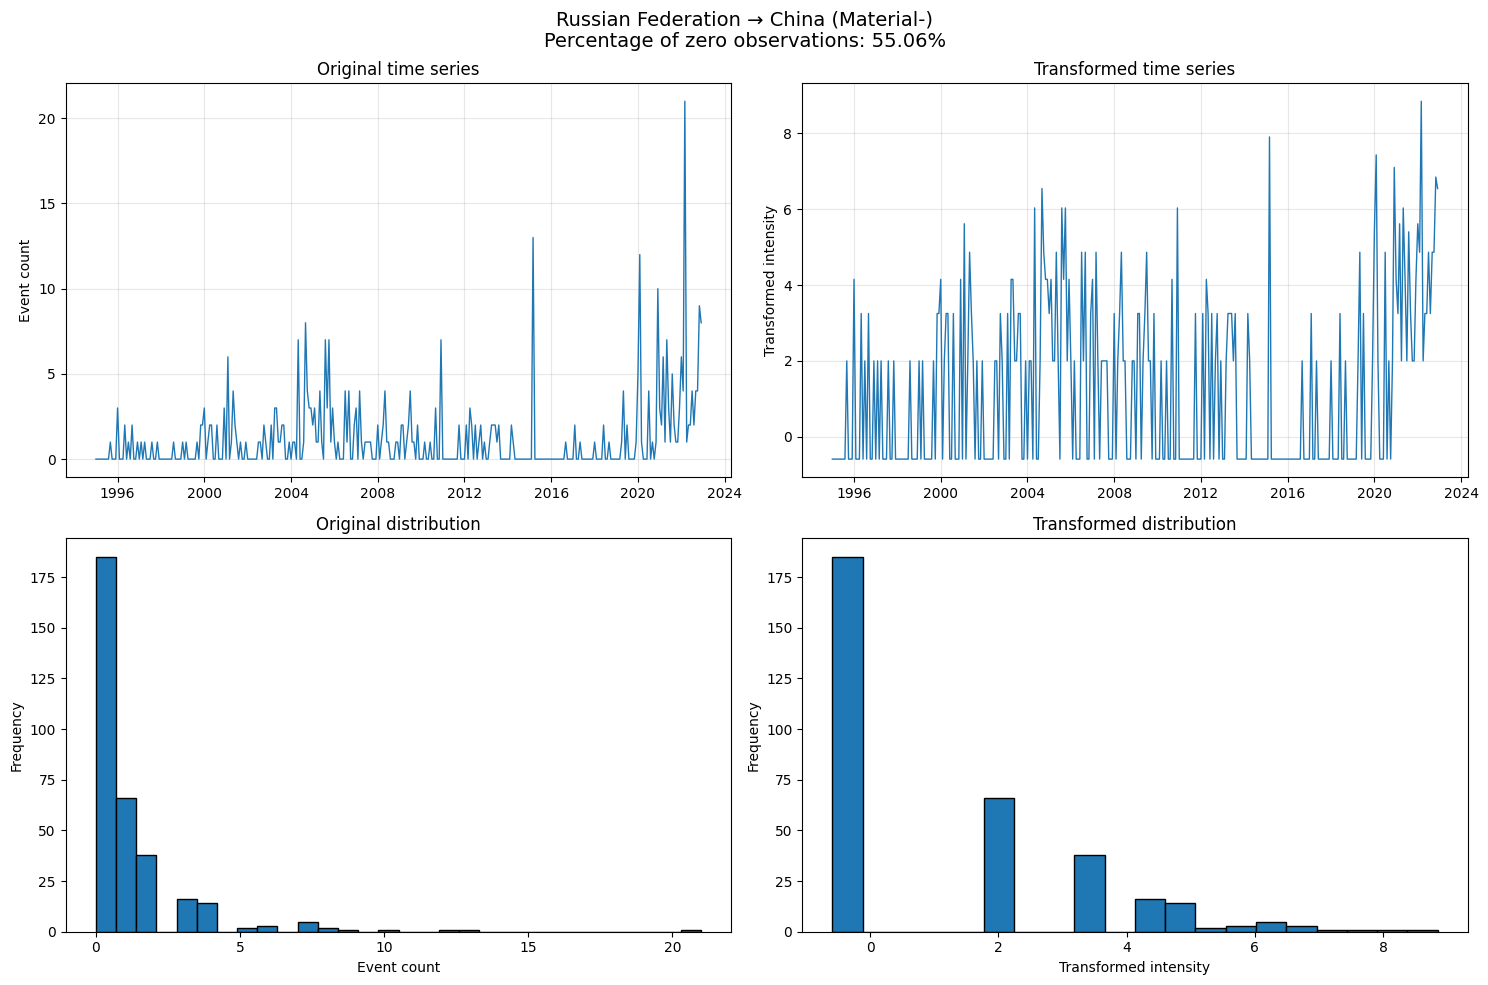

In [55]:

k = 0
i = 1
j = 2
original_series = Y_raw[k, i, j, :]
transformed_series = Y_normal[k, i, j, :]
origin = countries_top[i]
destination = countries_top[j]
layer = layers[k]
time_axis = pd.to_datetime(months)
zero_percentage = np.mean(original_series == 0) * 100
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
# 1. Original time series
axes[0, 0].plot(time_axis, original_series, linewidth=1)
axes[0, 0].set_title("Original time series")
axes[0, 0].set_ylabel("Event count")
axes[0, 0].grid(alpha=0.3)
axes[0, 1].plot(time_axis, transformed_series, linewidth=1)
axes[0, 1].set_title("Transformed time series")
axes[0, 1].set_ylabel("Transformed intensity")
axes[0, 1].grid(alpha=0.3)
axes[1, 0].hist(original_series,bins=30,edgecolor="black")
axes[1, 0].set_title("Original distribution")
axes[1, 0].set_xlabel("Event count")
axes[1, 0].set_ylabel("Frequency")
axes[1, 1].hist(transformed_series,bins=20,edgecolor="black")
axes[1, 1].set_title("Transformed distribution")
axes[1, 1].set_xlabel("Transformed intensity")
axes[1, 1].set_ylabel("Frequency")
fig.suptitle(
    f"{origin} → {destination} ({layer})\n"
    f"Percentage of zero observations: {zero_percentage:.2f}%",
    fontsize=14)
plt.tight_layout()
plt.show()